In [13]:
import sys
from pathlib import Path

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch, Polygon
from matplotlib.ticker import MaxNLocator, PercentFormatter

REPO_ROOT = Path.cwd().parent.parent
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [14]:
_ONEDRIVE = "OneDrive - Stichting Deltares"
_EGYPT_DIR = "PhD/Egypt_ERF_data"
results_dir = Path.home() / _ONEDRIVE / _EGYPT_DIR / "Results"
results_dir.mkdir(parents=True, exist_ok=True)

src_dir = Path("~").expanduser() / _ONEDRIVE / _EGYPT_DIR / "Data/map"
excel_path = Path("~").expanduser() / _ONEDRIVE / _EGYPT_DIR / "Data/data_correlation.xlsx"

In [15]:
locations = ['Blk_Air_7', 'Blk_Air_18', 'Blk_Air_42', 'Blk_Air_15'] #60-70 42,7, 32, 65, 2 and 70-80 65,7,32,2 # 'Blk_Air_2', 'Blk_Air_32', 'Blk_Air_17', 'Blk_Air_42', 'Blk_Air_50', 'Blk_Air_65'
# make the shared code in src/ importable even when the package is not pip-installed

legend_labels = {
    "Blk_Air_23": "Luxor (CU 23; 100% of women unpaid)",
    "Blk_Air_18": "Gharbia (CU 18; 69% of women unpaid)",
    "Blk_Air_42": "Ismailiya (CU 42; 39% of women unpaid)",
    'Blk_Air_15':"Damietta (CU 15; 26% of women unpaid)",
    "Blk_Air_7": "Suhag (CU 7; 100% of women unpaid)",
    "Blk_Air_2": "Behera (CU 2; 86% of women unpaid)",
    "Blk_Air_65": "Menia (CU 65; 73% of women unpaid)",
    "Blk_Air_32": "Gharbia (CU 32; 69% of women unpaid)",
    "Blk_Air_17": "Dakahlia (CU 17; 57% of women unpaid)",
    "Blk_Air_63": "Port Said-Ismailiya; CU 63 39% of women unpaid",
    "Blk_Air_50": "Dakahlia (CU 50; 57% of women unpaid)",
}


In [16]:
wage_df = pd.read_csv(results_dir / 'wage_by_command_unit.csv')
productivity_df = pd.read_csv(results_dir / 'group_productivity.csv', index_col=0)
map_df = wage_df.merge(productivity_df, on='area', how='left')

In [17]:
command_gdf = gpd.read_file(src_dir / 'Final2_Command_Area.shp')
conversion_df = pd.read_excel(excel_path, sheet_name='command_area')

mapping = conversion_df.merge(
    command_gdf[['Name', 'OBJECTID', 'geometry']],
    left_on = 'area_map_name',
    right_on = 'OBJECTID',
).set_index('area_name')["Name"]

In [18]:
map_df['area_name'] = map_df['area'].map(mapping)
map_df['geometry'] = map_df['area_name'].map(command_gdf.set_index('Name')['geometry'])
map_gdf = gpd.GeoDataFrame(map_df, geometry='geometry')

command_gdf['area'] = command_gdf["Name"].map(mapping)

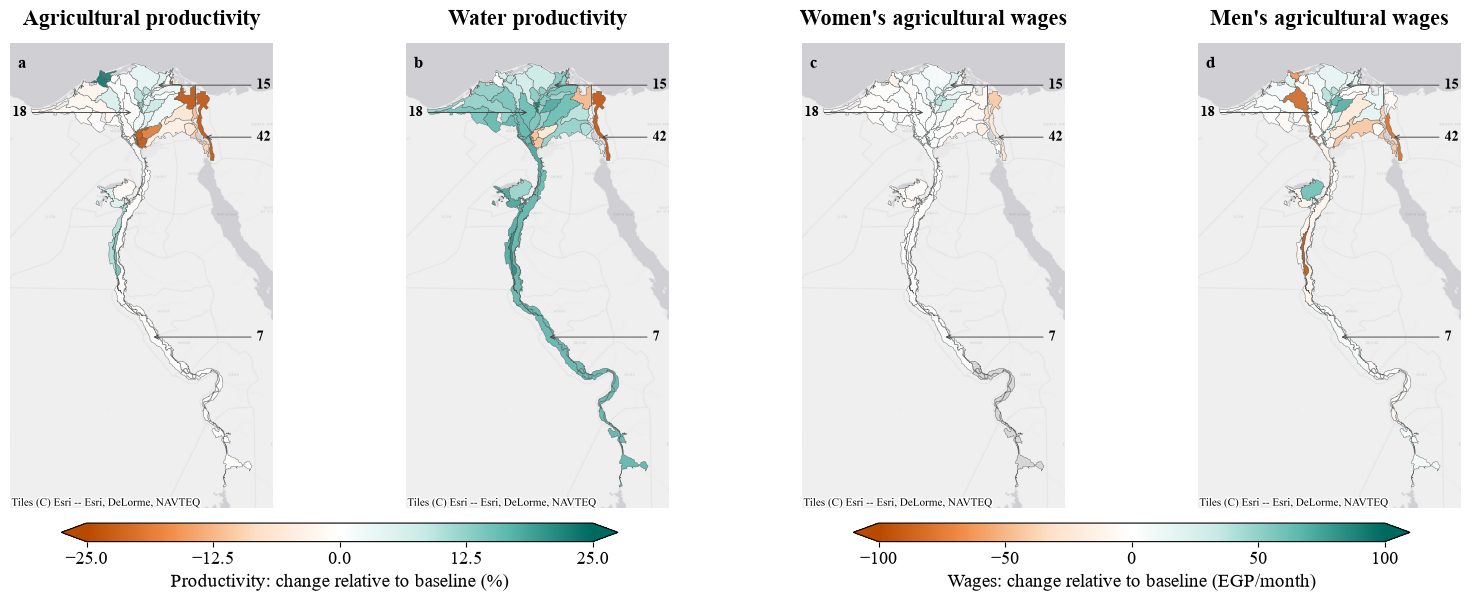

In [26]:
import contextily as cx
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize

baseline, scenarios = '60', ['70']
label_column = 'area'
label_adjustments = {}  # Example: {'15': ('right', 8), '18': ('left', -6)}
FIGURE_DIR = REPO_ROOT / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

panels = [('agricultural_productivity', 'Agricultural productivity', 'productivity'),
          ('water_productivity', 'Water productivity', 'productivity'),
          ('female', "Women's agricultural wages", 'wages'),
          ('male', "Men's agricultural wages", 'wages')]
vlims = {'productivity': 25, 'wages': 100}
cbar_labels = {'productivity': 'Productivity: change relative to baseline (%)',
               'wages': 'Wages: change relative to baseline (EGP/month)'}
cmap = LinearSegmentedColormap.from_list('orange_teal', ['#b84a00', '#f28e4b', '#fde0c5', '#ffffff', '#c9ebe6', '#5bb8ad', '#00695f'])
norms = {group: Normalize(-v, v) for group, v in vlims.items()}


def add_outside_labels(ax, labels, adjustments):
    # Convert points to fractions of the final panel width and height.
    pt = ax.figure.dpi / 72
    x_gap = -12 * pt / ax.bbox.width
    y_unit = pt / ax.bbox.height
    sides = {'left': [], 'right': []}

    for label, point in labels:
        x, y = ax.transAxes.inverted().transform(ax.transData.transform((point.x, point.y)))
        side, shift = adjustments.get(label, ('left' if x < 0.5 else 'right', 0))
        sides[side].append((y + shift * y_unit, label, point))

    for side, items in sides.items():
        if not items:
            continue
        items.sort(key=lambda item: item[0])
        bottom, top = 0.025, 0.975
        gap = min(15 * y_unit, (top - bottom) / max(1, len(items) - 1))
        heights = []
        for target_y, _, _ in items:
            heights.append(max(target_y, heights[-1] + gap if heights else bottom))
        heights[-1] = min(heights[-1], top)
        for i in range(len(heights) - 2, -1, -1):
            heights[i] = min(heights[i], heights[i + 1] - gap)

        left = side == 'left'
        for (_, label, point), y in zip(items, heights):
            ax.annotate(label, xy=(point.x, point.y), xycoords='data',
                        xytext=(-x_gap if left else 1 + x_gap, y), textcoords='axes fraction',
                        ha='right' if left else 'left', va='center', fontsize=10, fontweight='bold',
                        annotation_clip=False, clip_on=False, zorder=10,
                        arrowprops=dict(arrowstyle='->', color='0.25', lw=0.65, mutation_scale=8,
                                        shrinkA=2, shrinkB=0, relpos=(1 if left else 0, 0.5)))


plot_gdf = map_gdf.to_crs(epsg=3857).copy()
selected = plot_gdf.loc[plot_gdf[label_column].isin(locations), [label_column, plot_gdf.geometry.name]]
points = selected.dissolve(by=label_column).geometry.representative_point() if not selected.empty else {}
labels = [(str(name).split('_')[-1].strip(), point) for name, point in points.items()
          if point is not None and not point.is_empty]

minx, miny, maxx, maxy = plot_gdf.total_bounds
pad = 0.05 * max(maxx - minx, maxy - miny)

for scenario in scenarios:
    fig, axes = plt.subplots(1, 4, figsize=(16, 6.5), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.035, right=0.965, wspace=0.32)  # Space for labels between panels

    for ax, (var, title, group), letter in zip(axes, panels, 'abcd'):
        base = plot_gdf[f'{var}_{baseline}']
        diff = plot_gdf[f'{var}_{scenario}'] - base
        plot_gdf[f'{var}_diff'] = 100 * diff / base.where(base != 0) if group == 'productivity' else diff

        ax.set_xlim(minx - pad, maxx + pad)
        ax.set_ylim(miny - pad, maxy + pad)
        plot_gdf.plot(column=f'{var}_diff', ax=ax, cmap=cmap, norm=norms[group], alpha=0.85,
                      edgecolor='0.3', linewidth=0.3, missing_kwds=dict(color='lightgrey', edgecolor='0.3', linewidth=0.3))
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs=plot_gdf.crs, zoom=8)
        ax.set_title(title, fontweight='bold', y=1.02, pad=6)
        ax.text(0.03, 0.97, letter, transform=ax.transAxes, va='top', fontweight='bold', fontsize=12)
        ax.set_axis_off()

    for group, group_axes in [('productivity', axes[:2]), ('wages', axes[2:])]:
        v = vlims[group]
        cbar = fig.colorbar(ScalarMappable(norm=norms[group], cmap=cmap), ax=list(group_axes), orientation='horizontal',
                            fraction=0.04, pad=0.03, aspect=30, shrink=0.8, extend='both')
        cbar.set_label(cbar_labels[group])
        cbar.set_ticks([-v, -v / 2, 0, v / 2, v])

    fig.canvas.draw()
    for ax in axes:
        add_outside_labels(ax, labels, label_adjustments)

    fig.savefig(FIGURE_DIR / f'map_plots_{baseline}_{scenario}.png', dpi=300, bbox_inches='tight')
    plt.show()

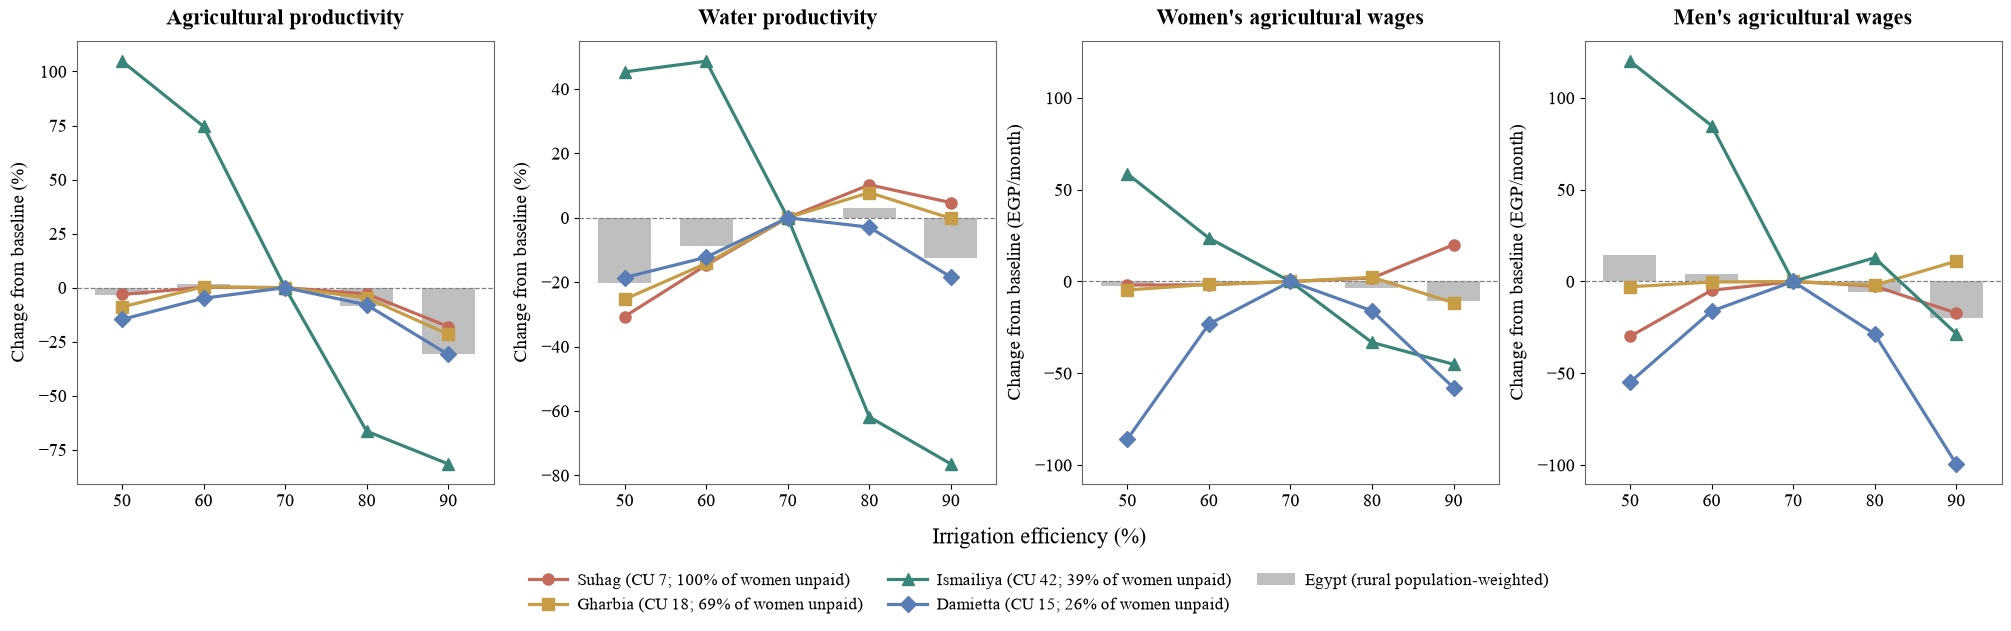

Saved: c:\Users\hermawan\OneDrive - Stichting Deltares\PhD\Egypt_ERF_data\egypt-survey-ml\figures\scenario_plot_multiple_locations.png


In [27]:

# Font settings
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"], "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14, "xtick.labelsize": 13,
    "ytick.labelsize": 13, "legend.fontsize": 12, "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Settings
scenarios = ["50", "60", "70", "80", "90"]
baseline = "70"
location_colors = ["#C46A5A", "#C69C45", "#398579", "#597DB5", "#9573AA", "#6F7645"]
location_markers = ["o", "s", "^", "D", "v", "P"]
location_column = "area"
weight_column = "rural_population"
min_baselines = {"agricultural_productivity": 0, "water_productivity": 0}

FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
panels = [
    ("agricultural_productivity", "Agricultural productivity", "productivity"),
    ("water_productivity", "Water productivity", "productivity"),
    ("female", "Women's agricultural wages", "wages"),
    ("male", "Men's agricultural wages", "wages"),
]

# Validate locations
if not locations:
    raise ValueError("Add at least one location to the locations list.")
rows = {}
for location in locations:
    selected = map_gdf.loc[map_gdf[location_column] == location]
    if len(selected) != 1:
        raise ValueError(f"Expected one row for '{location}', found {len(selected)}. Check map_gdf['{location_column}'].")
    rows[location] = selected.iloc[0]

# Figure: panels, shared x-label, shared legend
x = [int(s) for s in scenarios]
fig = plt.figure(figsize=(20, 6.2), constrained_layout=True)
grid = fig.add_gridspec(3, 4, height_ratios=[4, 0.35, 0.5])
axes = [fig.add_subplot(grid[0, i]) for i in range(4)]
xlabel_ax = fig.add_subplot(grid[1, :])
xlabel_ax.set_axis_off()
xlabel_ax.text(0.5, 0.5, "Irrigation efficiency (%)", ha="center", va="center", fontsize=16, transform=xlabel_ax.transAxes)
legend_ax = fig.add_subplot(grid[2, :])
legend_ax.set_axis_off()

# Background bars: rural population-weighted averages
weights = np.asarray(map_gdf[weight_column], dtype=float)
bar_width = min(np.diff(sorted(x))) * 0.65 if len(x) > 1 else 5

for ax, (var, title, group) in zip(axes, panels):
    baseline_values = np.asarray(map_gdf[f"{var}_{baseline}"], dtype=float)
    scenario_values = np.column_stack([np.asarray(map_gdf[f"{var}_{s}"], dtype=float) for s in scenarios])
    valid = np.isfinite(weights) & (weights > 0) & np.isfinite(baseline_values) & np.all(np.isfinite(scenario_values), axis=1)
    if not valid.any():
        raise ValueError(f"No areas with valid values and positive population for {var}.")
    baseline_mean = np.average(baseline_values[valid], weights=weights[valid])
    scenario_means = np.average(scenario_values[valid], axis=0, weights=weights[valid])
    overall_changes = scenario_means - baseline_mean
    if group == "productivity":
        if baseline_mean == 0 or abs(baseline_mean) < min_baselines[var]:
            overall_changes = np.zeros_like(scenario_means)
        else:
            overall_changes = overall_changes / baseline_mean * 100
    ax.bar(x, overall_changes, width=bar_width, color="#808080", alpha=0.5, edgecolor="none", zorder=1, label="Egypt (rural population-weighted)")

# Selected locations
for i, location in enumerate(locations):
    row = rows[location]
    color = location_colors[i % len(location_colors)]
    marker = location_markers[i % len(location_markers)]
    for ax, (var, title, group) in zip(axes, panels):
        values = np.array([row[f"{var}_{s}"] for s in scenarios], dtype=float)
        baseline_value = float(row[f"{var}_{baseline}"])
        change = values - baseline_value
        if group == "productivity":
            if baseline_value == 0 or abs(baseline_value) < min_baselines[var]:
                change = np.zeros_like(values)
            else:
                change = change / baseline_value * 100
        ax.plot(x, change, marker=marker, markersize=8, linewidth=2.3, color=color, markerfacecolor=color, markeredgecolor=color, markeredgewidth=1, label=legend_labels.get(location, location), zorder=3)

# Format panels
for ax, (_, title, group) in zip(axes, panels):
    ax.axhline(0, color="grey", linestyle="--", linewidth=0.9, zorder=2)
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xticks(x)
    ax.set_ylabel("Change from baseline (%)" if group == "productivity" else "Change from baseline (EGP/month)", labelpad=8)
    ax.set_axisbelow(True)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("#666666")
        spine.set_linewidth(0.8)

# Same y-axis range for women's and men's wages
ymin = min(axes[2].get_ylim()[0], axes[3].get_ylim()[0])
ymax = max(axes[2].get_ylim()[1], axes[3].get_ylim()[1])
axes[3].sharey(axes[2])
axes[2].set_ylim(ymin, ymax)

# Shared legend on one line
handles, labels = axes[0].get_legend_handles_labels()
#legend_ax.legend(handles, labels, loc="center", ncol=3, frameon=False, handlelength=2.3, columnspacing=1.5, handletextpad=0.6)
legend_ax.legend(handles, labels, loc="center", ncol=3, frameon=False,
                 handlelength=2.3, columnspacing=1.5, handletextpad=0.6)

# Save and show
output_path = FIGURE_DIR / "scenario_plot_multiple_locations.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {output_path}")

Showing 44 command areas. 7 fall outside the y-axis range.


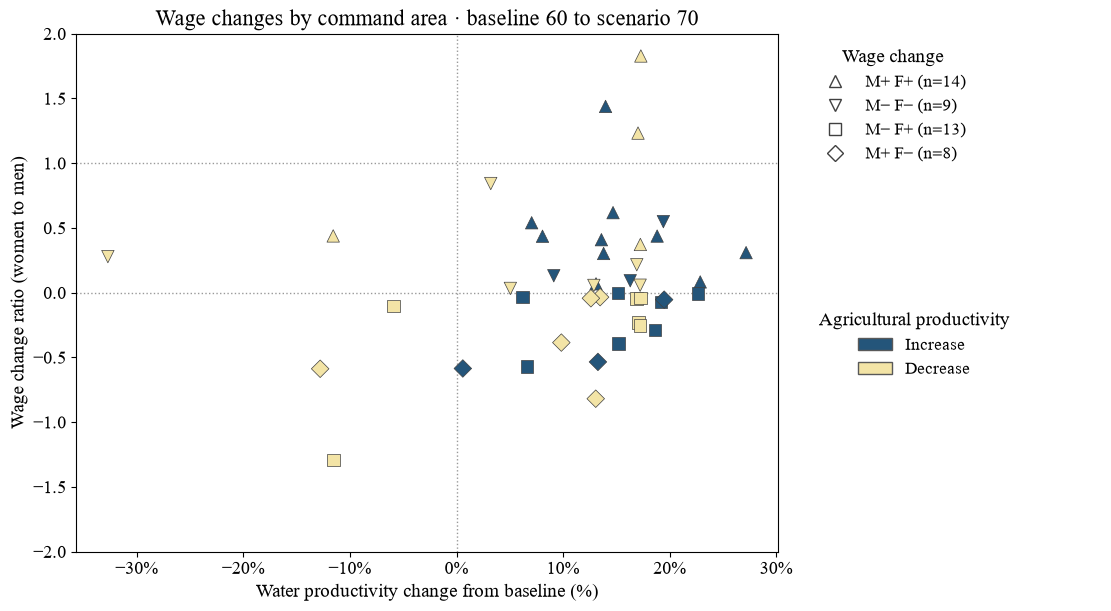

In [28]:
# Settings
baseline = 60
scenario = 70
y_limits = (-2, 2)  # Use None for the full range
locations = []     # Use None for all labels, or ["Blk_Air_51"] to label 51

colour_key = {
    "Increase": "#24557A",     # Blue
    "Decrease": "#F3E4A6",     # Yellow
    "No change": "#FFFFFF",    # White
    "Unavailable": "#BDBDBD",  # Grey
}

# Find the baseline water-productivity column
water_cols = [
    col for col in map_gdf.columns
    if col.startswith("water_pro")
    and "no_salinity" not in col
    and col.endswith(f"_{baseline}")
]
if len(water_cols) != 1:
    raise ValueError(f"Expected one baseline water-productivity column, found {water_cols}")

water_prefix = water_cols[0].rsplit("_", 1)[0]

def scenario_change(prefix, *, percent=False):
    base = pd.to_numeric(map_gdf[f"{prefix}_{baseline}"])
    end = pd.to_numeric(map_gdf[f"{prefix}_{scenario}"])
    change = end - base
    if percent:
        return 100 * change / base.where(base.ne(0))
    return change

changes = pd.DataFrame({
    "area": map_gdf["area"],
    "water_pct": scenario_change(water_prefix, percent=True),
    "agri_pct": scenario_change("agricultural_productivity", percent=True),
    "women_change": scenario_change("female"),
    "men_change": scenario_change("male"),
}).replace([np.inf, -np.inf], np.nan)

# Keep areas with a valid x-coordinate and a wage direction for both groups
complete = changes.dropna(subset=["water_pct", "women_change", "men_change"])
nonzero = complete["women_change"].ne(0) & complete["men_change"].ne(0)
points = complete.loc[nonzero].copy()
points["wage_ratio"] = points["women_change"] / points["men_change"]

# Colour depends only on the sign of agricultural productivity change
points["agri_direction"] = "Unavailable"
points.loc[points["agri_pct"] > 0, "agri_direction"] = "Increase"
points.loc[points["agri_pct"] < 0, "agri_direction"] = "Decrease"
points.loc[points["agri_pct"] == 0, "agri_direction"] = "No change"
points["colour"] = points["agri_direction"].map(colour_key)

if y_limits is None:
    visible = points
else:
    ymin, ymax = y_limits
    if ymin >= ymax:
        raise ValueError("The lower y-axis limit must be smaller than the upper limit.")
    visible = points.loc[points["wage_ratio"].between(ymin, ymax)]

print(f"Showing {len(visible)} command areas. "
      f"{len(points) - len(visible)} fall outside the y-axis range.")

women_up = visible["women_change"].gt(0)
men_up = visible["men_change"].gt(0)
groups = [
    ("M+ F+",  men_up & women_up,  "^"),
    ("M− F−", ~men_up & ~women_up, "v"),
    ("M− F+", ~men_up & women_up,  "s"),
    ("M+ F−",  men_up & ~women_up, "D"),
]

fig = plt.figure(figsize=(11, 6), constrained_layout=True)
grid = fig.add_gridspec(2, 2, width_ratios=[3.3, 1.4])
ax = fig.add_subplot(grid[:, 0])
shape_ax = fig.add_subplot(grid[0, 1])
colour_ax = fig.add_subplot(grid[1, 1])
shape_ax.set_axis_off()
colour_ax.set_axis_off()

ax.axvline(0, color="0.6", linestyle=":", linewidth=1, zorder=0)
for y in (0, 1):
    ax.axhline(y, color="0.6", linestyle=":", linewidth=1, zorder=0)

shape_handles = []
for label, mask, marker in groups:
    group = visible.loc[mask]
    ax.scatter(
        group["water_pct"], group["wage_ratio"],
        marker=marker, s=80, c=group["colour"].tolist(),
        edgecolors="0.25", linewidths=0.5, zorder=2,
    )
    shape_handles.append(
        Line2D(
            [], [], linestyle="none", marker=marker, markersize=8,
            markerfacecolor="white", markeredgecolor="0.25",
            label=f"{label} (n={len(group)})",
        )
    )

selected = visible if locations is None else visible.loc[visible["area"].isin(locations)]
for row in selected.itertuples():
    ax.annotate(
        str(row.area).rsplit("_", 1)[-1],
        (row.water_pct, row.wage_ratio),
        xytext=(5, 4), textcoords="offset points", fontsize=9,
        fontweight="bold" if row.women_change > 0 and row.men_change > 0 else "normal",
    )

if y_limits is not None:
    ax.set_ylim(*y_limits)

ax.xaxis.set_major_locator(MaxNLocator(nbins=7, integer=True, min_n_ticks=1))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set(
    xlabel="Water productivity change from baseline (%)",
    ylabel="Wage change ratio (women to men)",
    title=f"Wage changes by command area · baseline {baseline} to scenario {scenario}",
)

shape_ax.legend(
    handles=shape_handles, title="Wage change",
    loc="upper left", frameon=False,
)

used = set(visible["agri_direction"])
colour_handles = [
    Patch(facecolor=colour, edgecolor="0.35", label=label)
    for label, colour in colour_key.items()
    if label in used
]
if colour_handles:
    colour_ax.legend(
        handles=colour_handles, title="Agricultural productivity",
        loc="upper left", frameon=False,
    )

plt.show()
fig.savefig(FIGURE_DIR / "point.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()

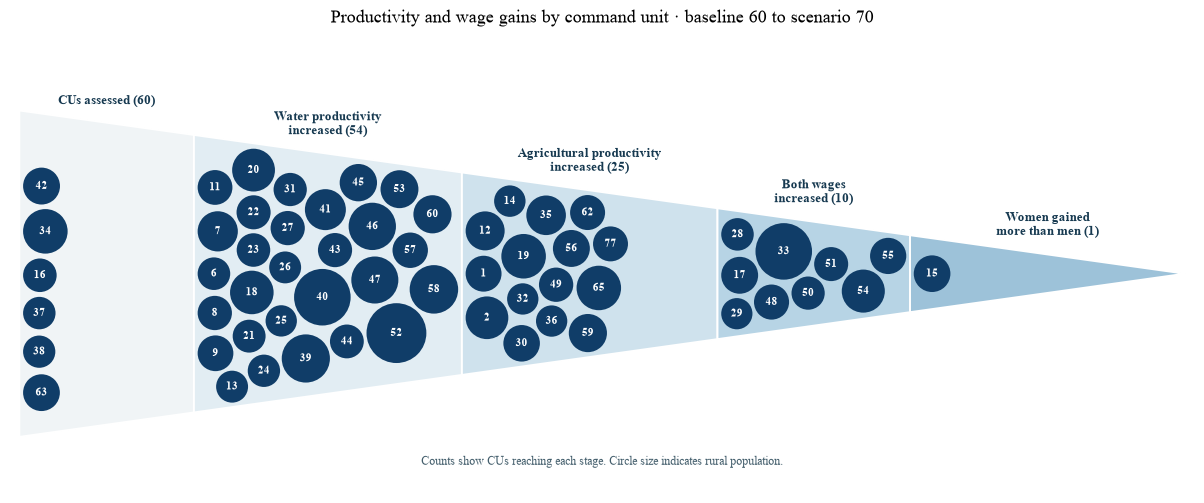

CUs assessed: 60 reached | 6 circles | CUs: 16, 34, 37, 38, 42, 63
Water productivity increased: 54 reached | 29 circles | CUs: 6, 7, 8, 9, 11, 13, 18, 20, 21, 22, 23, 24, 25, 26, 27, 31, 39, 40, 41, 43, 44, 45, 46, 47, 52, 53, 57, 58, 60
Agricultural productivity increased: 25 reached | 15 circles | CUs: 1, 2, 12, 14, 19, 30, 32, 35, 36, 49, 56, 59, 62, 65, 77
Both wages increased: 10 reached | 9 circles | CUs: 17, 28, 29, 33, 48, 50, 51, 54, 55
Women gained more than men: 1 reached | 1 circles | CUs: 15


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon

baseline, scenario = 60, 70
population_col, ball_colour, gap = "rural_population", "#103D68", 0.055
min_radius, max_radius = 0.25, 0.48
slope, edge_pad = 0.14, 0.06
heading_widths = [2.8, 3.6, 4.1, 2.8, 3.4]
fills = ["#F0F4F6", "#E2EDF3", "#CFE2ED", "#B7D4E5", "#9DC2D9"]

# Read indicators and calculate changes from baseline.
if population_col not in map_gdf:
    candidates = [c for c in map_gdf.columns if "pop" in c.lower() or "rural" in c.lower()]
    raise KeyError(f"Missing population column {population_col!r}. Possible columns: {candidates}")

water_cols = [c for c in map_gdf if c.startswith("water_pro") and "no_salinity" not in c and c.endswith(f"_{baseline}")]
if len(water_cols) != 1:
    raise ValueError(f"Expected one baseline water-productivity column, found {water_cols}")

def scenario_change(prefix, percent=False):
    base = pd.to_numeric(map_gdf[f"{prefix}_{baseline}"], errors="raise")
    diff = pd.to_numeric(map_gdf[f"{prefix}_{scenario}"], errors="raise") - base
    return 100 * diff / base.where(base.ne(0)) if percent else diff

data = pd.DataFrame({
    "area": map_gdf["area"], "population": pd.to_numeric(map_gdf[population_col], errors="raise"),
    "water_pct": scenario_change(water_cols[0].rsplit("_", 1)[0], percent=True),
    "agri_pct": scenario_change("agricultural_productivity", percent=True),
    "women_change": scenario_change("female"), "men_change": scenario_change("male"),
}).replace([np.inf, -np.inf], np.nan).dropna(subset=["area"]).drop_duplicates()

duplicates = data.loc[data["area"].duplicated(keep=False), "area"].unique()
if len(duplicates):
    raise ValueError(f"Conflicting values for these command units: {duplicates.tolist()}")
if data["population"].lt(0).any():
    raise ValueError("Rural population counts must be nonnegative.")

data["unit"] = data["area"].astype(str).str.rsplit("_", n=1).str[-1]
data = data.assign(sort_id=pd.to_numeric(data["unit"], errors="coerce")).sort_values(["sort_id", "area"])
assessed = data.loc[data["water_pct"].notna()].copy()

# Circle area scales with population above a minimum size for readability.
largest_pop = assessed["population"].max()
share = assessed["population"].fillna(0) / largest_pop if pd.notna(largest_pop) and largest_pop > 0 else 0
assessed["radius"] = np.sqrt(min_radius**2 + share * (max_radius**2 - min_radius**2))
assessed["missing_pop"] = assessed["population"].isna()

# Stage counts are cumulative. Each circle appears only in the last stage its CU reached.
water_up = assessed.loc[assessed["water_pct"] > 0]
agri_up = water_up.loc[water_up["agri_pct"] > 0]
both_up = agri_up.loc[(agri_up["women_change"] > 0) & (agri_up["men_change"] > 0)]
women_gained_more = both_up.loc[both_up["women_change"] > both_up["men_change"]]
stages = [("CUs assessed", assessed), ("Water productivity\nincreased", water_up),
          ("Agricultural productivity\nincreased", agri_up), ("Both wages\nincreased", both_up),
          ("Women gained\nmore than men", women_gained_more)]
groups = [current.loc[~current["area"].isin(following["area"])]
          for (_, current), (_, following) in zip(stages, stages[1:])] + [women_gained_more]
assert sum(map(len, groups)) == len(assessed)

def pack_triangle(length):
    sections, left = [], 0.0
    for group, min_width in zip(groups, heading_widths):
        placed, right = [], left + min_width
        for item in group.itertuples():
            r = item.radius
            first_x = left + edge_pad + r
            clearance = (r + edge_pad) * np.hypot(1, slope)
            ymax = slope * (length - first_x) - clearance
            if ymax < 0:
                return None

            # At each height, find the leftmost position clear of earlier circles.
            best = None
            ys = np.linspace(-ymax, ymax, max(3, int(2 * ymax / 0.05) + 1))
            for y in sorted(ys, key=abs):
                x, blocked = first_x, []
                for px, py, previous_r, _, _ in placed:
                    distance, dy = r + previous_r + gap, abs(y - py)
                    if dy < distance:
                        dx = np.sqrt(distance**2 - dy**2)
                        blocked.append((px - dx, px + dx))
                for lo, hi in sorted(blocked):
                    if lo < x < hi:
                        x = hi
                if abs(y) + clearance <= slope * (length - x) and (best is None or x < best[0]):
                    best = (x, y)

            if best is None:
                return None
            x, y = best
            placed.append((x, y, r, item.unit, item.missing_pop))
            right = max(right, x + r + edge_pad)
        if right > length:
            return None
        sections.append((left, right, placed))
        left = right
    return sections

length = sum(heading_widths)
sections = pack_triangle(length)
while sections is None:
    length += 0.5
    sections = pack_triangle(length)

# Draw the funnel and its population-sized circles.
half_height, fig_width = slope * length, max(12, length * 0.53)
fig, ax = plt.subplots(figsize=(fig_width, (2 * half_height + 2.5) * fig_width / length))
ax.set(aspect="equal", xlim=(-0.15, length + 0.15), ylim=(-half_height - 0.9, half_height + 1.3))
ax.set_axis_off()

for i, ((left, right, placed), (heading, reached)) in enumerate(zip(sections, stages)):
    end = length if i == len(stages) - 1 else right
    h_left, h_right = slope * (length - left), slope * (length - end)
    corners = [(left, h_left), (end, h_right), (end, -h_right), (left, -h_left)]
    ax.add_patch(Polygon(corners, closed=True, facecolor=fills[i], edgecolor="white", linewidth=1.4))
    middle = (left + end) / 2
    ax.text(middle, slope * (length - middle) + 0.25, f"{heading} ({len(reached)})",
            ha="center", va="bottom", fontsize=9, fontweight="bold", color="#163950")
    for x, y, r, unit, missing_pop in placed:
        ax.add_patch(Circle((x, y), r, facecolor="#788793" if missing_pop else ball_colour, edgecolor="none"))
        ax.text(x, y, unit, ha="center", va="center", fontsize=8, fontweight="bold", color="white")

note = "Counts show CUs reaching each stage. Circle size indicates rural population."
if assessed["missing_pop"].any():
    note += " Grey indicates missing population."
ax.text(length / 2, -half_height - 0.4, note, ha="center", va="center", fontsize=8.5, color="#425D6B")
ax.set_title(f"Productivity and wage gains by command unit · baseline {baseline} to scenario {scenario}", fontsize=13, pad=5)
fig.tight_layout(pad=0.4)
# fig.savefig("command_unit_funnel.png", dpi=300, bbox_inches="tight")
plt.show()

for (heading, reached), shown in zip(stages, groups):
    name, units = heading.replace("\n", " "), ", ".join(shown["unit"]) or "none"
    print(f"{name}: {len(reached)} reached | {len(shown)} circles | CUs: {units}")

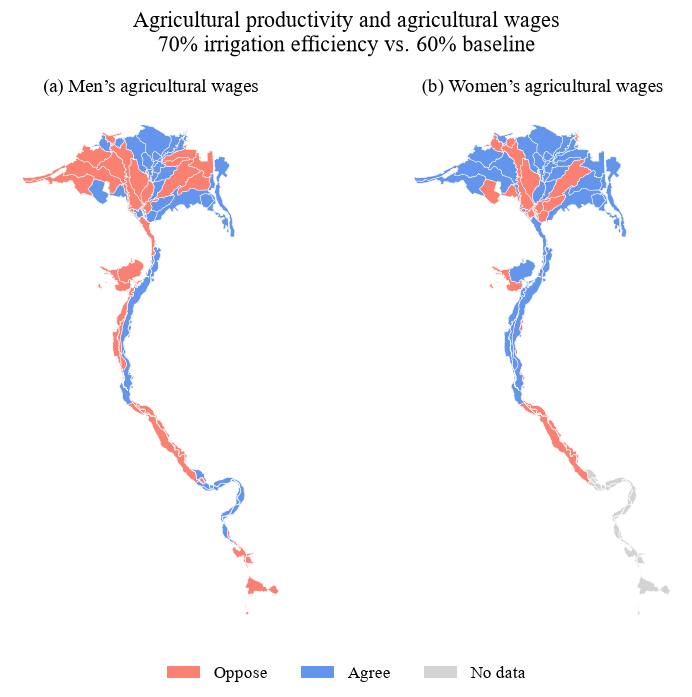

In [31]:
baseline, scenario = "60", "70"
gdf = map_gdf.to_crs(epsg=3857).copy()
colors = {"Oppose": "#FA8072", "Agree": "#6495ED", "No data": "#D3D3D3"}

# Agricultural productivity change is the same for both panels
prod_base = gdf[f"agricultural_productivity_{baseline}"]
prod_change = gdf[f"agricultural_productivity_{scenario}"] - prod_base

fig, axes = plt.subplots(1, 2, figsize=(8, 7), sharex=True, sharey=True)
panels = [("male", "(a) Men’s agricultural wages"), ("female", "(b) Women’s agricultural wages")]

for ax, (sex, title) in zip(axes, panels):
    wage_change = gdf[f"{sex}_{scenario}"] - gdf[f"{sex}_{baseline}"]
    valid = (prod_base > 0) & np.isfinite(prod_change) & np.isfinite(wage_change)

    column = f"agreement_{sex}"
    gdf[column] = "No data"
    gdf.loc[valid, column] = np.where(np.sign(prod_change[valid]) == np.sign(wage_change[valid]), "Agree", "Oppose")

    gdf.plot(ax=ax, color=gdf[column].map(colors), edgecolor="white", linewidth=0.35)
    ax.set_title(title, fontsize=14)
    ax.set_axis_off()

fig.suptitle(f"Agricultural productivity and agricultural wages\n{scenario}% irrigation efficiency vs. {baseline}% baseline", fontsize=16)
handles = [Patch(facecolor=color, label=label) for label, color in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=12)
fig.subplots_adjust(top=0.85, bottom=0.08, left=0.02, right=0.98, wspace=0.04)

output_path = REPO_ROOT / "figures" / f"agricultural_productivity_male_female_wages_agreement_{scenario}_vs_{baseline}.png"
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()